In [328]:

# IMPORTATION DES PACKAGES
import random
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# 1) Choisir un nombre de sommets entre 50 et 100
N = random.randint(50, 100)

#  Choisir une probabilité d’arête aléatoire (plus elle est grande, plus le graphe est dense)
p = random.uniform(0.03, 0.07)

#  Graine aléatoire (pour reproductibilité si besoin)
seed = random.randint(50, 100)




In [330]:
# Générer un graphe orienté aléatoire de type Erdős–Rényi
G = nx.gnp_random_graph(N, p, seed=seed, directed=True)

#  Afficher quelques infos
print(f"Graphe orienté généré :")
print(f"- N (sommets) = {G.number_of_nodes()}")
print(f"- m (arêtes) = {G.number_of_edges()}")
print(f"- p ≈ {p:.4f}")
print(f"- densité = {nx.density(G):.5f}")
print(f"- seed = {seed}")


Graphe orienté généré :
- N (sommets) = 66
- m (arêtes) = 246
- p ≈ 0.0572
- densité = 0.05734
- seed = 50


In [331]:
# Affichage des différentes possibilités de liaisons ( edges )
D = nx.edges(G)
D = pd.DataFrame(D)
display( D.head(20))

,0,1
0,0,57
1,0,58
2,1,6
3,1,20
4,1,23
5,1,35
6,1,40
7,1,46
8,1,51
9,1,56


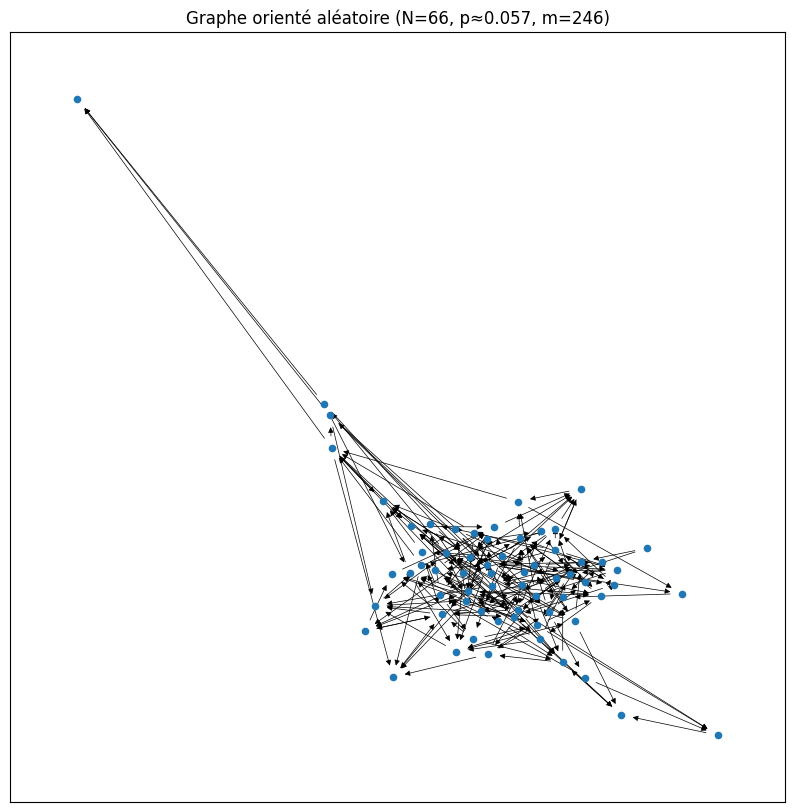

In [332]:

# Visualisation
plt.figure(figsize=(10, 10))
pos = nx.spring_layout(G, seed=42)  # mise en page stable
nx.draw_networkx_nodes(G, pos, node_size=20) # Taille des noeuds
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=8, width=0.5) # paramétrage des flèches
plt.title(f"Graphe orienté aléatoire (N={N}, p≈{p:.3f}, m={G.number_of_edges()})")
plt.axis('on')
plt.show()

In [333]:

# ETAPE 0 : IMPORTATIONS

import time                          # gérer les pauses entre requêtes (politesse)
from collections import deque        # file FIFO pour le crawl (BFS)
from urllib.parse import urljoin, urlparse, urldefrag  # outils URL (relatif→absolu, parser, enlever #)
import re                            # expressions régulières pour filtrer des extensions (pdf, images, etc.)
import numpy as np                   # pour générer un délai aléatoire (loi uniforme)
import requests                      # client HTTP (GET pages web)
from bs4 import BeautifulSoup        # parsing HTML (extraction des liens)
import networkx as nx                # graphes orientés + PageRank




In [334]:


# ETAPE 1 : CONFIGURATIONS INITIALES

START_URL = "https://ecogestion.univ-paris13.fr/"
# l'URL de départ, c'est la page d'où on commence l'exploration (le "crawl")

ALLOWED_NETLOCS = {"ecogestion.univ-paris13.fr"}  # domaine(s) interne(s) autorisés
# on restreint volontairement le crawl à ce/ces domaine(s) pour éviter de sortir du site

MAX_PAGES = 120                                 # limite de pages à crawler
# garde-fou pour ne pas tout aspirer ni surcharger le serveur

REQ_TIMEOUT = 10                                # temps max (en secondes) pour qu’une requête réponde
# si la page met trop de temps, on abandonne pour ne pas bloquer le programme

# délai entre deux requêtes : base fixe + partie aléatoire (loi uniforme) pour un comportement non robotique
SLEEP_BASE = 0.3                                # base minimale de pause
SLEEP_JITTER_MAX = 0.5                          # on tirera un U[0, 0.5] à CHAQUE requête (voir ETAPE 4)

USER_AGENT = (
    "PR-Scraper/1.0 "
    "(compatible; audit PageRank universitaire; "
    "+https://github.com/filou337/page-ranking)"
)
# Liaison au GitHub filou337 (profil personnel) → transparence côté serveur

# Filtre d'URL : pas de mail_to/tel/, ni fichiers lourds (pdf, images…)
SKIP_EXT = re.compile(r"\.(pdf|png|jpg|jpeg|gif|svg|zip|rar|7z|mp4|mp3|docx?|xlsx?)$", re.I)
# re.compile = on prépare la regex UNE fois pour la réutiliser plusieurs fois rapidement
# re.I = insensible à la casse (".PDF" = ".pdf", etc.)

session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT})
# session HTTP réutilisable (keep-alive, cookies) + on fixe l'User-Agent par défaut pour toutes les requêtes




In [335]:


# ETAPE 2 : FONCTIONS UTILITAIRES

def canonical(u: str, strip_query: bool = True) -> str:
    """
    Normaliser une URL pour éviter les doublons.
    - on enlève le fragment (#ancre)
    - on force schéma + host en minuscules
    - on retire la query si strip_query=True
    - on retire le slash final
    """
    u, _ = urldefrag(u)
    p = urlparse(u)
    core = f"{p.scheme.lower()}://{p.netloc.lower()}{p.path}"
    if not strip_query and p.query:
        core = f"{core}?{p.query}"
    return core.rstrip("/")


def is_internal(u: str) -> bool:
    """
    Vérifie que l'URL est interne (dans ALLOWED_NETLOCS).
    - on compare le netloc (host) en ignorant 'www.'
    """
    host = urlparse(u).netloc.lower()
    if host.startswith("www."):
        host = host[4:]
    return host in ALLOWED_NETLOCS


def good_href(h: str) -> bool:
    """
    Filtre les 'href' non exploitables :
    - schémas non web : mailto:, tel:, javascript:
    - ancres locales : '#...'
    - extensions lourdes définies par SKIP_EXT
    """
    if not h or h.startswith(("mailto:", "tel:", "javascript:", "#")):
        return False
    path = urlparse(h).path
    return SKIP_EXT.search(path) is None


def is_html_response(resp: requests.Response) -> bool:
    """Vérifie qu'on a bien une page HTML (Content-Type)"""
    return "text/html" in (resp.headers.get("Content-Type") or "").lower()



In [336]:


# ETAPE 3 : TELECHARGER UNE PAGE (FETCHER)

def fetch_html(url: str) -> str | None:
    """
    Télécharge une page avec la session HTTP.
    - timeout REQ_TIMEOUT
    - on ne garde que le HTML
    - on ajoute un délai de politesse : SLEEP_BASE + U[0, SLEEP_JITTER_MAX]
    """
    try:
        r = session.get(url, timeout=REQ_TIMEOUT, allow_redirects=True)
        if r.status_code == 200 and is_html_response(r):
            # on s'aligne sur l'encodage "détecté" si besoin
            r.encoding = r.apparent_encoding or r.encoding
            return r.text
        return None
    except requests.RequestException:
        return None
    finally:
        time.sleep(SLEEP_BASE + np.random.uniform(0, SLEEP_JITTER_MAX))



In [337]:


# ETAPE 4 : EXTRAIRE DES LIENS "DE CONTENU" D'UNE PAGE

def extract_content_links(html: str, base_url: str) -> set[str]:
    """
    On veut éviter que le graphe soit dominé par le header/footer (menus identiques partout).
    - on retire header/footer/nav/aside/widgets/scripts/styles
    - on cible la zone principale : <main>, <article>, .entry-content, #content, .content
    - on ne garde que des liens internes, web, non lourds
    - on limite éventuellement à K liens pour éviter les 'pages aspirateurs'
    """
    soup = BeautifulSoup(html, "html.parser")

    # 1) Retirer les zones de navigation / répétées
    for sel in [
        "header", "footer", "nav", "aside",
        ".menu", ".navbar", ".widget",
        ".wp-block-navigation", ".breadcrumbs", ".breadcrumb",
        "[role='navigation']",
        "script", "style"
    ]:
        for tag in soup.select(sel):
            tag.decompose()

    # 2) Zone de contenu la plus probable
    root = soup.select_one("main, article, .entry-content, #content, .content") or soup

    links = set()
    for a in root.select("a[href]"):
        href = a["href"].strip()
        if not good_href(href):
            continue
        v = urljoin(base_url, href)                 # lien relatif → absolu
        if urlparse(v).scheme not in ("http", "https"):
            continue
        if not is_internal(v):
            continue
        links.add(canonical(v))                     # on normalise pour éviter les doublons

    # 3) (Option) couper à K liens max par page pour éviter un graphe trop dense (menus très riches)
    K = 60
    if len(links) > K:
        links = set(list(links)[:K])

    return links



In [338]:


# ETAPE 5 : CRAWL (BFS) + CONSTRUCTION GRAPHE

G = nx.DiGraph()                           # graphe orienté (pages = noeuds, liens = arêtes)
to_visit = deque([canonical(START_URL)])   # file FIFO (BFS) initialisée avec l'URL de départ
seen = {canonical(START_URL)}              # ensemble des URLs déjà vues (évite revisites)

while to_visit and len(seen) < MAX_PAGES:
    # la boucle continue tant qu'il y a des pages à visiter et qu'on n'a pas atteint la limite
    u = to_visit.popleft()                 # on prend la page en tête de file
    html = fetch_html(u)                   # on télécharge le HTML (ou None en cas d'échec)
    G.add_node(u)                          # on enregistre le noeud (même si la page échoue)

    if not html:
        continue                           # pas de HTML → on ne peut pas extraire de liens, on passe

    outlinks = extract_content_links(html, u)  # extraction "contenu" (pas les menus)
    for v in outlinks:
        G.add_edge(u, v, weight=2.0)       # on pèse un peu plus les liens "de contenu" (meilleur PR)
        if v not in seen and len(seen) < MAX_PAGES:
            seen.add(v)                    # on marque comme vue
            to_visit.append(v)             # et on la met dans la file à visiter

# Petit résumé du graphe collecté
print(f"Noeuds: {G.number_of_nodes()}  |  Arêtes: {G.number_of_edges()}")



Noeuds: 31  |  Arêtes: 54


In [371]:


# ETAPE 6 : CALCUL DU PAGERANK
# On calcule le PageRank pondéré :
# - alpha=0.90 : probabilité de "suivre un lien" (le reste = téléportation aléatoire)
# - weight="weight" : on utilise le poids des arêtes ajouté plus haut
pr = nx.pagerank(G, alpha=0.90, weight="weight")

# Conversion de la variable pr en DataFrame
pr_df = pd.DataFrame(list(pr.items()))

# Tri décroissant et affichage des 10 pages les plus "centrales"
top10 = sorted(pr.items(), key=lambda x: x[1], reverse=True)[:10]

print("\nTop 10 PageRank (interne) :")
for page, score in top10:
    print(f"{score:.6f}  {page}")


Top 10 PageRank (interne) :
0.425593  https://ecogestion.univ-paris13.fr/candidatures
0.021701  https://ecogestion.univ-paris13.fr/masters-formation-initiale-fi
0.021701  https://ecogestion.univ-paris13.fr/licence
0.021701  https://ecogestion.univ-paris13.fr/masters-formation-apprentissage-fa
0.021576  https://ecogestion.univ-paris13.fr/parcours-comptabilite-controle-audit
0.019948  https://ecogestion.univ-paris13.fr/m1-m2-fa-parcours-risques-bancaires-supervision
0.019948  https://ecogestion.univ-paris13.fr/parcours-marketing-digital-apprentissage
0.019948  https://ecogestion.univ-paris13.fr/m1-m2-parcours-conseil-en-entreprise-fa
0.019948  https://ecogestion.univ-paris13.fr/m1-m2-fa-parcours-conformite-et-gestion-des-risques
0.019948  https://ecogestion.univ-paris13.fr/m1-m2-fa-parcours-ccpro-expertise-conseiller-patrimonial-agence


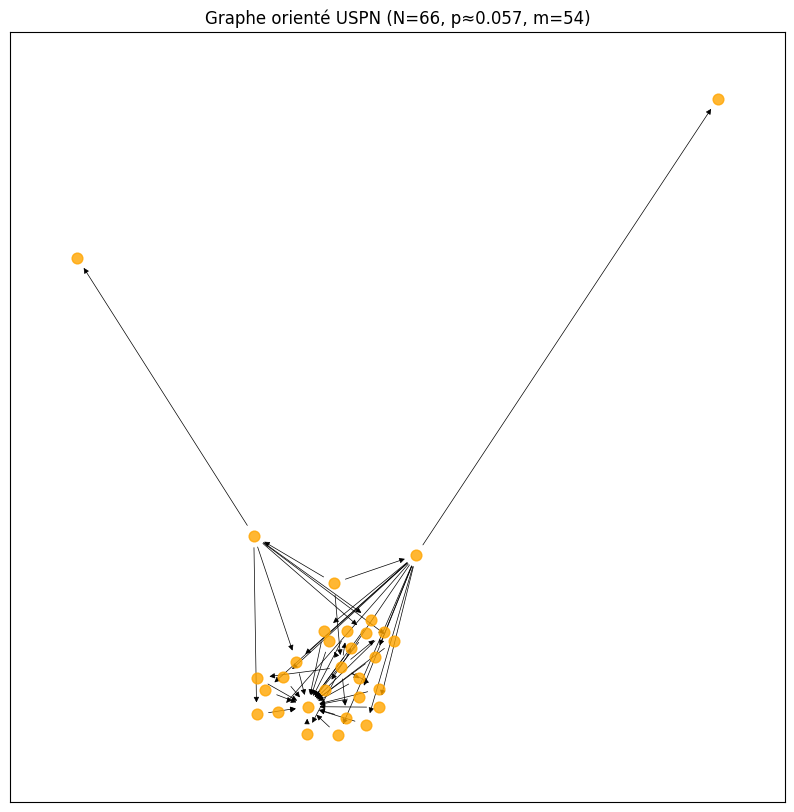

In [359]:
# ETAPE 7: REPRESENTATION DU GRAPHE

plt.figure(figsize=(10, 10))
pos = nx.spring_layout(G, seed=42)  # mise en page stable
nx.draw_networkx_nodes(G, pos, node_size=60, alpha=0.8, node_color= 'orange') # Taille des noeuds
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=8, width=0.5) # paramétrage des flèches
plt.title(f"Graphe orienté USPN (N={G.number_of_nodes()}, m={G.number_of_edges()})")
plt.axis('on')
plt.show()